In [1]:
import torch
from torch import nn, optim

In [2]:
import numpy as np

In [3]:
import pandas as pd

In [4]:
import math

In [5]:
import matplotlib.pyplot as plt

In [6]:
from string import punctuation

In [7]:
from sklearn.feature_extraction.text import CountVectorizer

In [8]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Baixe o pacote de dados necessário (apenas na primeira execução)
nltk.download('punkt_tab')

# 1. Baixe o pacote de dados de stopwords (necessário apenas na primeira vez)
nltk.download('stopwords')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\anton\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\anton\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [9]:
# 2. Carregue a lista de stopwords em inglês
stopwords_temp = stopwords.words('english')
stopwords_temp.extend( ['—', '’'] )
stopwords_ingles = set(stopwords_temp)

In [10]:
df = pd.read_csv("C:\\git\\dados\\nlp\\news_sentiment_analysis.csv", encoding="utf-8")
df = df[["Title", "Description", "Sentiment"]]
df

,Title,Description,Sentiment
0,Pine View High teacher wins Best in State awar...,"ST. GEORGE — Kaitlyn Larson, a first-year teac...",positive
1,Businesses Face Financial Strain Amid Liquidit...,"Harare, Zimbabwe – Local businesses are grappl...",neutral
2,Musk donates to super pac working to elect Tru...,(marketscreener.com) Billionaire Elon Musk has...,positive
3,US FTC issues warning to franchisors over unfa...,(marketscreener.com) A U.S. trade regulator on...,negative
4,Rooftop solar's dark side,4.5 million households in the U.S. have solar ...,positive
...,...,...,...
3495,"Arrow Electronics, Inc. (NYSE:ARW) Shares Purc...",QRG Capital Management Inc. increased its stak...,positive
3496,"3,120 Shares in NICE Ltd. (NASDAQ:NICE) Bought...",QRG Capital Management Inc. bought a new posit...,positive
3497,"QRG Capital Management Inc. Has $857,000 Stock...",QRG Capital Management Inc. boosted its stake ...,positive
3498,Biotechnology Market: Surging Investments and ...,"WESTFORD, Mass., July 18, 2024 /PRNewswire/ --...",neutral


In [11]:
df["Sentiment"].unique()

<StringArray>
['positive', 'neutral', 'negative']
Length: 3, dtype: str

In [12]:
df["sentiment_number"] = df["Sentiment"].map( {"positive": 1.0, "negative": 0.0, "neutral": 0.0 } )
df

,Title,Description,Sentiment,sentiment_number
0,Pine View High teacher wins Best in State awar...,"ST. GEORGE — Kaitlyn Larson, a first-year teac...",positive,1.0
1,Businesses Face Financial Strain Amid Liquidit...,"Harare, Zimbabwe – Local businesses are grappl...",neutral,0.0
2,Musk donates to super pac working to elect Tru...,(marketscreener.com) Billionaire Elon Musk has...,positive,1.0
3,US FTC issues warning to franchisors over unfa...,(marketscreener.com) A U.S. trade regulator on...,negative,0.0
4,Rooftop solar's dark side,4.5 million households in the U.S. have solar ...,positive,1.0
...,...,...,...,...
3495,"Arrow Electronics, Inc. (NYSE:ARW) Shares Purc...",QRG Capital Management Inc. increased its stak...,positive,1.0
3496,"3,120 Shares in NICE Ltd. (NASDAQ:NICE) Bought...",QRG Capital Management Inc. bought a new posit...,positive,1.0
3497,"QRG Capital Management Inc. Has $857,000 Stock...",QRG Capital Management Inc. boosted its stake ...,positive,1.0
3498,Biotechnology Market: Surging Investments and ...,"WESTFORD, Mass., July 18, 2024 /PRNewswire/ --...",neutral,0.0


In [13]:
def limpar_texto( texto ):
    tokens_limpas = []
    tabela = str.maketrans("", "", punctuation)
    texto_limpo = texto.lower().translate( tabela )
    tokens = word_tokenize(texto_limpo)
    for token in tokens:
        if token not in stopwords_ingles:
            tokens_limpas.append( token )
    return " ".join(tokens_limpas)
            

In [14]:
limpar_texto(df["Description"][0])

'st george kaitlyn larson firstyear teacher pine view high school recently received best state award business leadership course larson students grades 1012 highest passing rate youscience exam spring fall semesters 2023 youscience exam similar final exams 8230'

In [15]:
df["descricao_limpa"] = df["Description"].apply( limpar_texto )
df

,Title,Description,Sentiment,sentiment_number,descricao_limpa
0,Pine View High teacher wins Best in State awar...,"ST. GEORGE — Kaitlyn Larson, a first-year teac...",positive,1.0,st george kaitlyn larson firstyear teacher pin...
1,Businesses Face Financial Strain Amid Liquidit...,"Harare, Zimbabwe – Local businesses are grappl...",neutral,0.0,harare zimbabwe – local businesses grappling s...
2,Musk donates to super pac working to elect Tru...,(marketscreener.com) Billionaire Elon Musk has...,positive,1.0,marketscreenercom billionaire elon musk donate...
3,US FTC issues warning to franchisors over unfa...,(marketscreener.com) A U.S. trade regulator on...,negative,0.0,marketscreenercom us trade regulator fridayann...
4,Rooftop solar's dark side,4.5 million households in the U.S. have solar ...,positive,1.0,45 million households us solar panels homes cu...
...,...,...,...,...,...
3495,"Arrow Electronics, Inc. (NYSE:ARW) Shares Purc...",QRG Capital Management Inc. increased its stak...,positive,1.0,qrg capital management inc increased stake sha...
3496,"3,120 Shares in NICE Ltd. (NASDAQ:NICE) Bought...",QRG Capital Management Inc. bought a new posit...,positive,1.0,qrg capital management inc bought new position...
3497,"QRG Capital Management Inc. Has $857,000 Stock...",QRG Capital Management Inc. boosted its stake ...,positive,1.0,qrg capital management inc boosted stake akama...
3498,Biotechnology Market: Surging Investments and ...,"WESTFORD, Mass., July 18, 2024 /PRNewswire/ --...",neutral,0.0,westford mass july 18 2024 prnewswire accordin...


In [16]:
MAX_PALAVRAS = 3000

In [17]:
vetorizador = CountVectorizer(max_features = MAX_PALAVRAS)

In [18]:
X = vetorizador.fit_transform( df["descricao_limpa"] )
X.toarray()

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(3500, 3000))

In [20]:
dicionario = vetorizador.get_feature_names_out()
dicionario

array(['000', '001', '038', ..., 'überkauft', 'überverkauft',
       'überwiegend'], shape=(3000,), dtype=object)

In [35]:
modelo = nn.Sequential(
    nn.Linear(in_features = MAX_PALAVRAS, out_features = 1),
    nn.Sigmoid()
)
modelo

Sequential(
  (0): Linear(in_features=3000, out_features=1, bias=True)
  (1): Sigmoid()
)

In [36]:
perda = nn.BCELoss()
perda

BCELoss()

In [37]:
otimizador = optim.SGD( modelo.parameters(), lr = 0.01)
otimizador

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)

In [38]:
entrada = torch.tensor( X.toarray(), dtype=torch.float32 )
entrada

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]])

In [39]:
saida = torch.tensor( [df["sentiment_number"]], dtype=torch.float32 )
saida.T

tensor([[1.],
        [0.],
        [1.],
        ...,
        [1.],
        [0.],
        [1.]])

In [40]:
epocas = 500
perdas = []
for epoca in range( epocas ):
    y_hat = modelo( entrada )
    loss = perda(y_hat, saida.T)
    perdas.append( loss.tolist() )
    print(loss)
    otimizador.zero_grad()
    loss.backward()
    otimizador.step()

tensor(0.6933, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6924, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6915, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6907, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6898, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6890, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6881, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6873, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6865, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6856, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6848, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6840, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6832, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6824, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6816, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6809, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6801, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6793, grad_fn=<BinaryCrossEntropyBackward0>)
tensor(0.6786, grad_fn=<Bina

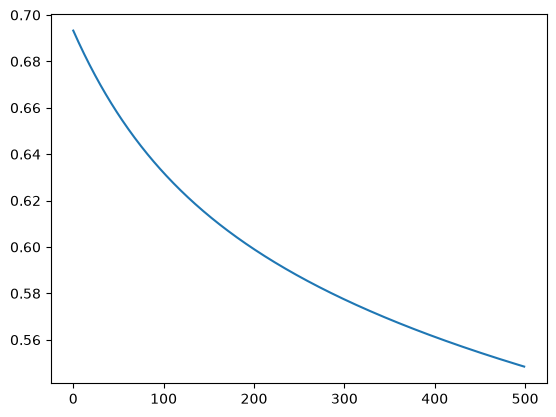

In [41]:
plt.plot( perdas )
plt.show()

In [45]:
vetorizador_teste = CountVectorizer(max_features=MAX_PALAVRAS, vocabulary=dicionario)

'45 million households us solar panels homes customers happy electricity bills disappeared great planet thousands thousands people really disappointed theyve sold panels expensive say hard get someone come fix break turns sometimes crummy customer experience accident ties back big national solar companies built businesses first place entice people'

In [61]:
acertos = 0
for item_teste in range(1000, 2000):
    # item_teste = 4
    texto = df["descricao_limpa"][item_teste]
    X_teste = vetorizador_teste.fit_transform( [texto] )
    X_teste = torch.tensor(X_teste.toarray(), dtype=torch.float32)
    y_hat = modelo(X_teste)
    y = df["sentiment_number"][item_teste]
    resultado = 1.0 if y_hat > 0.50 else 0.0
    if resultado == y:
        acertos = acertos + 1
        # print("acertou")
    else:
        pass
        # print("errou")
    
print(f"Porcentagem de acertos: {100*acertos/1000:.2f}%")

Porcentagem de acertos: 64.60%
